In [1]:
import jax
import jax.numpy as jnp
from jax import random
from jax.experimental.ode import odeint

# 64-bit precision
jax.config.update("jax_enable_x64", True)

import numpy as np                 
import matplotlib.pyplot as plt
from pathlib import Path

np.set_printoptions(precision=4, suppress=True)
SEED = 42                          # fixed so every run (and every grader) gets the same numbers
print(f"JAX {jax.__version__}  |  backend: {jax.default_backend()}")

JAX 0.9.2  |  backend: cpu


In [2]:
import os
print(os.getcwd())

c:\Users\User\Downloads\lorenz-digital-twin


## Step 1  Simulate the Lorenz system


The Lorenz system is three coupled ODEs ( model for atmospheric convection)

$$
\dot x = \sigma(y-x), \qquad
\dot y = x(\rho - z) - y, \qquad
\dot z = xy - \beta z .
$$


In [16]:
#  parameters and config
SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0
X0 = jnp.array([-8.0, 7.0, 27.0])
T_END, DT = 10.0, 0.01

t = jnp.linspace(0.0, T_END, int(round(T_END / DT)) + 1)   # 1001 points
N = t.shape[0]


def lorenz_rhs(state, t, sigma=SIGMA, rho=RHO, beta=BETA):
    # Right-hand side f(state) of the Lorenz ODE (JAX signature: f(state, t)).
    x, y, z = state
    return jnp.array([sigma * (y - x),
                      x * (rho - z) - y,
                      x * y - beta * z])


X_clean = odeint(lorenz_rhs, X0, t, rtol=1e-9, atol=1e-9)   # shape (N, 3): columns x, y, z

# D1.1
print("X_clean.shape =", X_clean.shape)
assert X_clean.shape == (1001, 3)

X_clean.shape = (1001, 3)


## Step 2  Visualise the attractor



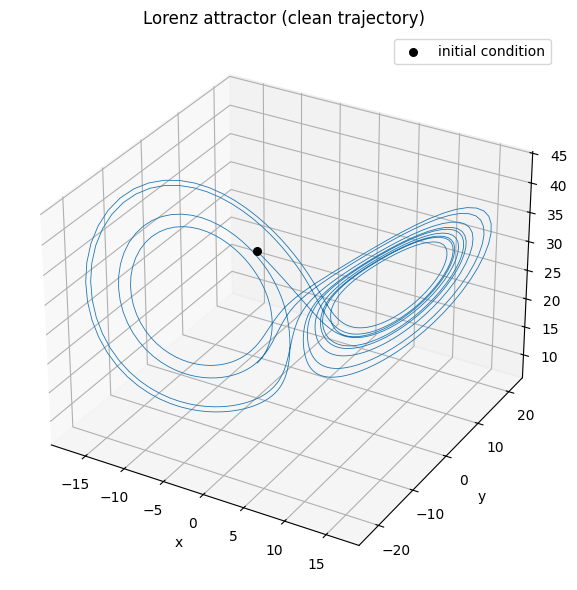

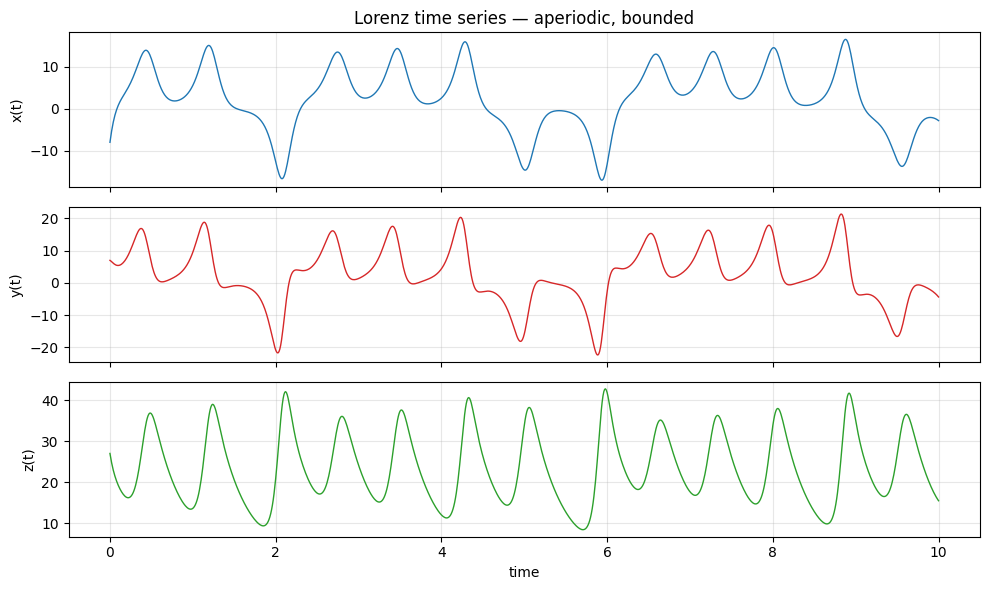

In [17]:
STATE_NAMES = ["x", "y", "z"]
COLORS = ["#1f77b4", "#d62728", "#2ca02c"]

# 3-D phase portrait
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(*X_clean.T, lw=0.6, color="#1f77b4")
ax.scatter(*X0, color="black", s=30, label="initial condition")
ax.set(xlabel="x", ylabel="y", zlabel="z", title="Lorenz attractor (clean trajectory)")
ax.legend()
plt.tight_layout(); plt.savefig("lorenz_attractor.png", dpi=150); plt.show()

# Time series on three stacked subplots
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, X_clean[:, i], color=COLORS[i], lw=1)
    ax.set_ylabel(f"{STATE_NAMES[i]}(t)"); ax.grid(alpha=0.3)
axes[0].set_title("Lorenz time series — aperiodic, bounded")
axes[-1].set_xlabel("time")
plt.tight_layout(); plt.savefig("lorenz_timeseries.png", dpi=150); plt.show()

## Step 3  Add measurement noise



$$
X_{\text{noisy}} = X_{\text{clean}} + \varepsilon, \qquad \varepsilon_{ij} \sim \mathcal N(0, \sigma_\varepsilon^2), \quad \sigma_\varepsilon = 0.01 .
$$





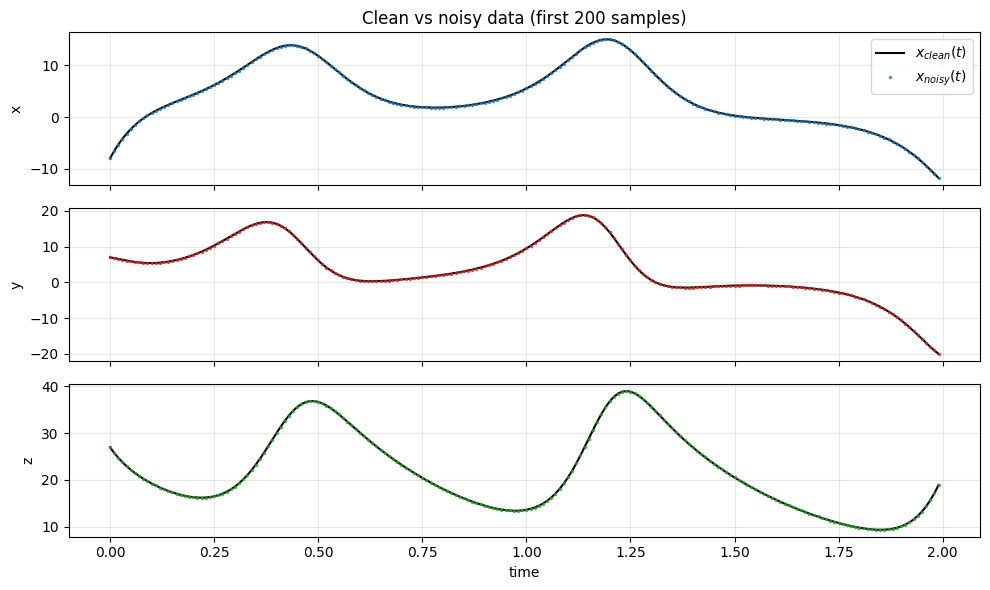

In [22]:
NOISE_STD = 0.01
key = random.PRNGKey(SEED)
key, noise_key = random.split(key)          

X_noisy = X_clean + NOISE_STD * random.normal(noise_key, X_clean.shape)

# D1.2 — overlay on a 200-point window
w = slice(0, 200)
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t[w], X_clean[w, i], color="black", lw=1.5, label=r"$x_{clean}(t)$")
    ax.plot(t[w], X_noisy[w, i], ".", color=COLORS[i], ms=3, alpha=0.7, label=r"$x_{noisy}(t)$")
    ax.set_ylabel(STATE_NAMES[i]); ax.grid(alpha=0.3)
axes[0].legend(loc="upper right"); axes[0].set_title("Clean vs noisy data (first 200 samples)")
axes[-1].set_xlabel("time")
plt.tight_layout(); plt.show()

## Step 4  Estimate the time derivatives $\dot X$



In [23]:
def finite_difference_4th(X, dt):
    # 4th-order central differences in the interior; 2nd-order at the 2 edge points on each side.
    interior = (-X[4:] + 8 * X[3:-1] - 8 * X[1:-3] + X[:-4]) / (12 * dt)
    Xdot = jnp.zeros_like(X).at[2:-2].set(interior)
    Xdot = Xdot.at[1].set((X[2] - X[0]) / (2 * dt))                     # central
    Xdot = Xdot.at[-2].set((X[-1] - X[-3]) / (2 * dt))
    Xdot = Xdot.at[0].set((-3 * X[0] + 4 * X[1] - X[2]) / (2 * dt))     # one-sided
    Xdot = Xdot.at[-1].set((3 * X[-1] - 4 * X[-2] + X[-3]) / (2 * dt))
    return Xdot


Xdot = finite_difference_4th(X_noisy, DT)

# Sanity check against the exact derivative (possible only because we know the truth).
# jax.vmap applies lorenz_rhs to every row at once — no Python loop.
Xdot_true = jax.vmap(lambda s: lorenz_rhs(s, 0.0))(X_clean)
print("RMS derivative error per state:", np.asarray(jnp.sqrt(jnp.mean((Xdot - Xdot_true) ** 2, axis=0))))
print("Typical |dX/dt| magnitude     :", np.asarray(jnp.abs(Xdot_true).mean(axis=0)))

RMS derivative error per state: [0.9384 0.9161 0.9689]
Typical |dX/dt| magnitude     : [36.699  47.7318 65.2126]


## Step 5  Build the polynomial feature library $\Theta(X)$

### The key idea of SINDy


$$
\underbrace{\dot X}_{N\times 3} \;=\; \underbrace{\Theta(X)}_{N\times 10}\;\underbrace{\Xi}_{10\times 3}.
$$


$$
\Theta(X) = \big[\,1,\; x,\; y,\; z,\; x^2,\; xy,\; xz,\; y^2,\; yz,\; z^2\,\big].
$$



In [25]:
FEATURE_NAMES = ["1", "x", "y", "z", "x^2", "xy", "xz", "y^2", "yz", "z^2"]


def build_poly_library(X):
    # Degree-2 polynomial library for a 3 state system -> shape (N, 10)
    x, y, z = X[:, 0], X[:, 1], X[:, 2]
    return jnp.stack([
        jnp.ones_like(x),         # 1
        x, y, z,                  # linear
        x * x, x * y, x * z,      # quadratic
        y * y, y * z, z * z,
    ], axis=1)


Theta = build_poly_library(X_noisy)

# D1.3
print("Theta.shape =", Theta.shape)
print("Features    :", FEATURE_NAMES)
assert Theta.shape == (1001, 10)

Theta.shape = (1001, 10)
Features    : ['1', 'x', 'y', 'z', 'x^2', 'xy', 'xz', 'y^2', 'yz', 'z^2']


## Step 6 — Sparse regression with STLSQ



1. Solve least squares: $\Xi = \Theta^{\dagger}\dot X$.
2. **Hard threshold:** set $\Xi_{ij} = 0$ wherever $|\Xi_{ij}| < \lambda$.
3. **Refit:** for each equation, redo least squares using only the surviving columns.
4. **Repeat** until the set of surviving terms (the *active support*) stops changing.



In [27]:
def stlsq(Theta, Xdot, threshold, max_iter=20):
    # Sequentially Thresholded Least Squares. Returns (Xi, iterations_used).
    Xi = jnp.linalg.lstsq(Theta, Xdot, rcond=None)[0]           # 1. dense start

    for it in range(1, max_iter + 1):
        small = jnp.abs(Xi) < threshold                          # 2. which terms to kill
        Xi = jnp.where(small, 0.0, Xi)                           #    (new array, no mutation)

        for k in range(Xdot.shape[1]):                           # 3. refit each equation
            keep = ~small[:, k]
            if jnp.any(keep):
                coef = jnp.linalg.lstsq(Theta[:, keep], Xdot[:, k], rcond=None)[0]
                Xi = Xi.at[keep, k].set(coef)

        if jnp.array_equal(jnp.abs(Xi) < threshold, small):     # 4. support unchanged -> done
            return Xi, it
    return Xi, max_iter


LAMBDA = 0.1
Xi, n_iter = stlsq(Theta, Xdot, LAMBDA)
print(f"STLSQ converged in {n_iter} iteration(s)\n")


def print_xi_table(Xi, title="Coefficient matrix Xi"):
    print(title)
    print(f"{'feature':>8} | {'dx/dt':>10} {'dy/dt':>10} {'dz/dt':>10}")
    print("-" * 44)
    for name, row in zip(FEATURE_NAMES, np.asarray(Xi)):
        print(f"{name:>8} | " + " ".join(f"{v:>10.4f}" for v in row))


# D1.4
print_xi_table(Xi)

STLSQ converged in 2 iteration(s)

Coefficient matrix Xi
 feature |      dx/dt      dy/dt      dz/dt
--------------------------------------------
       1 |     0.0000     0.0000     0.0000
       x |   -10.0017    27.9863     0.0000
       y |    10.0007    -0.9946     0.0000
       z |     0.0000     0.0000    -2.6665
     x^2 |     0.0000     0.0000     0.0000
      xy |     0.0000     0.0000     0.9999
      xz |     0.0000    -0.9997     0.0000
     y^2 |     0.0000     0.0000     0.0000
      yz |     0.0000     0.0000     0.0000
     z^2 |     0.0000     0.0000     0.0000


## Step 7 Inspect the recovered equations



In [28]:
EQS = ["dx/dt", "dy/dt", "dz/dt"]
IDX = {n: i for i, n in enumerate(FEATURE_NAMES)}


def equations_as_text(Xi, names=FEATURE_NAMES, lhs=EQS):
    Xi = np.asarray(Xi)
    lines = []
    for k, state in enumerate(lhs):
        terms = [f"{c:+.4f}*{n}" if n != "1" else f"{c:+.4f}"
                 for c, n in zip(Xi[:, k], names) if c != 0]
        lines.append(f"{state} = " + (" ".join(terms) if terms else "0"))
    return "\n".join(lines)


print("Recovered model:\n" + equations_as_text(Xi))

# Ground-truth coefficient matrix built from the known parameters 
Xi_true = (jnp.zeros((10, 3))
           .at[IDX["x"], 0].set(-SIGMA).at[IDX["y"], 0].set(SIGMA)
           .at[IDX["x"], 1].set(RHO).at[IDX["y"], 1].set(-1.0).at[IDX["xz"], 1].set(-1.0)
           .at[IDX["z"], 2].set(-BETA).at[IDX["xy"], 2].set(1.0))
print("\nTrue model:\n" + equations_as_text(Xi_true))

# D1.5 — relative error for every true non-zero term
print(f"\n{'equation':>8} {'term':>5} | {'true':>9} {'recovered':>10} {'rel. error':>11}")
print("-" * 52)
for i, k in zip(*np.nonzero(np.asarray(Xi_true))):
    true, est = float(Xi_true[i, k]), float(Xi[i, k])
    print(f"{EQS[k]:>8} {FEATURE_NAMES[i]:>5} | {true:9.4f} {est:10.4f} {abs(est-true)/abs(true):10.4%}")

# Structural check, switch off exactly the right terms?
true_terms = Xi_true != 0
same_support = bool(jnp.array_equal(Xi != 0, true_terms))
max_rel = float(jnp.max(jnp.where(true_terms, jnp.abs(Xi - Xi_true) / jnp.abs(jnp.where(true_terms, Xi_true, 1.0)), 0.0)))
print(f"\nCorrect set of terms identified: {same_support}")
print(f"Largest relative error         : {max_rel:.4%}  (target < 1%)")

# Parameter estimates handed to Phase 2
sigma_hat = (Xi[IDX["y"], 0] - Xi[IDX["x"], 0]) / 2     # average of the two sigma entries
rho_hat   = Xi[IDX["x"], 1]
beta_hat  = -Xi[IDX["z"], 2]
params = jnp.array([sigma_hat, rho_hat, beta_hat])
print(f"\nEstimated (sigma, rho, beta) = ({sigma_hat:.4f}, {rho_hat:.4f}, {beta_hat:.4f})")

Recovered model:
dx/dt = -10.0017*x +10.0007*y
dy/dt = +27.9863*x -0.9946*y -0.9997*xz
dz/dt = -2.6665*z +0.9999*xy

True model:
dx/dt = -10.0000*x +10.0000*y
dy/dt = +28.0000*x -1.0000*y -1.0000*xz
dz/dt = -2.6667*z +1.0000*xy

equation  term |      true  recovered  rel. error
----------------------------------------------------
   dx/dt     x |  -10.0000   -10.0017    0.0169%
   dy/dt     x |   28.0000    27.9863    0.0488%
   dx/dt     y |   10.0000    10.0007    0.0072%
   dy/dt     y |   -1.0000    -0.9946    0.5433%
   dz/dt     z |   -2.6667    -2.6665    0.0051%
   dz/dt    xy |    1.0000     0.9999    0.0065%
   dy/dt    xz |   -1.0000    -0.9997    0.0271%

Correct set of terms identified: True
Largest relative error         : 0.5433%  (target < 1%)

Estimated (sigma, rho, beta) = (10.0012, 27.9863, 2.6665)


## Step 8  Simulate the identified model



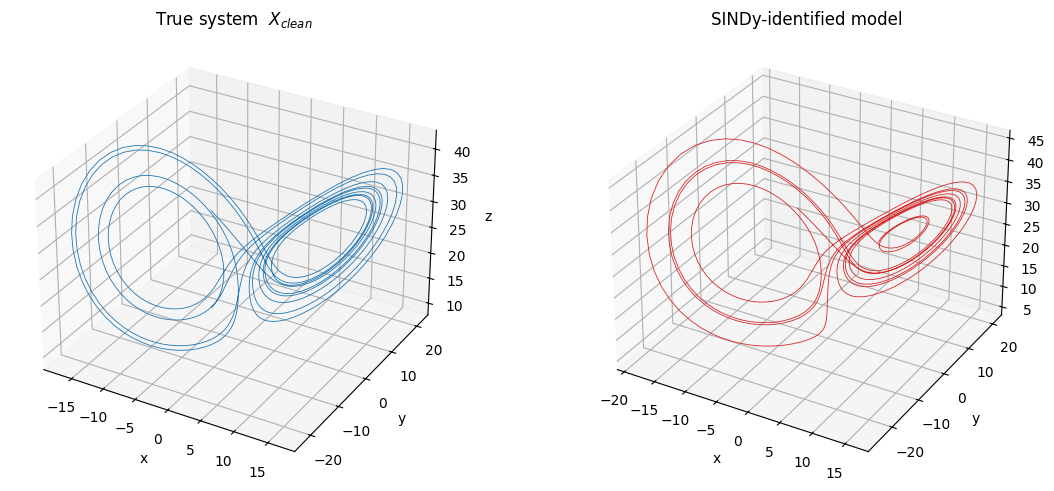

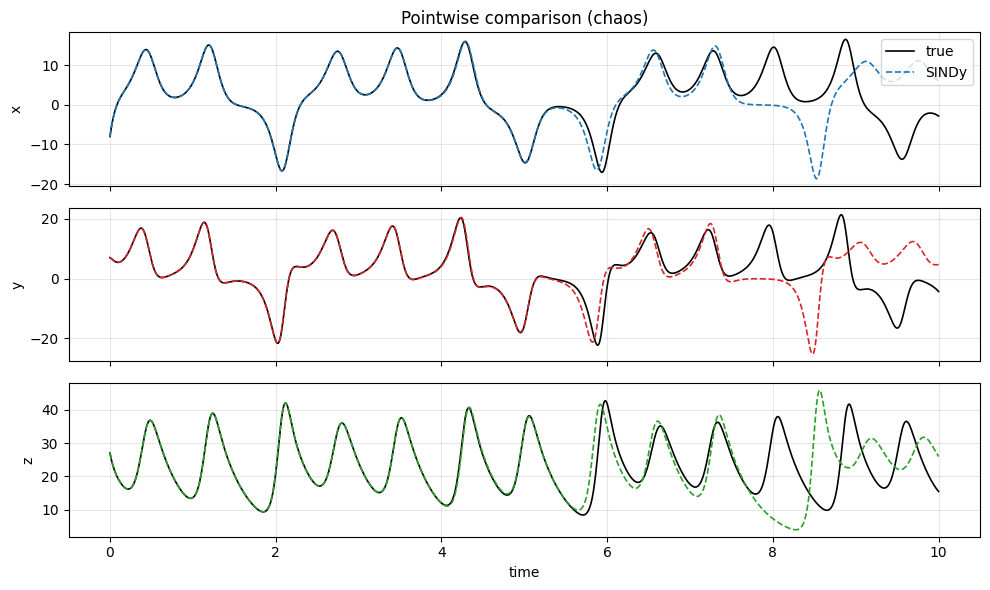

Trajectories stay within distance 1 until t ≈ 4.15


In [ ]:
def sindy_rhs(state, t, Xi):
    # Discovered model: d(state)/dt = Theta(state) @ Xi
    return (build_poly_library(state[None, :]) @ Xi)[0]


X_sindy = odeint(sindy_rhs, X0, t, Xi, rtol=1e-9, atol=1e-9)   # extra args (Xi) go after t

# D1.6 — side-by-side 3-D attractors
fig = plt.figure(figsize=(12, 5))
for j, (data, title, c) in enumerate([(X_clean, "True system  $X_{clean}$", "#1f77b4"),
                                      (X_sindy, "SINDy-identified model", "#d62728")]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.plot(*data.T, lw=0.6, color=c)
    ax.set(xlabel="x", ylabel="y", zlabel="z", title=title)
plt.tight_layout(); plt.savefig("lorenz_true_vs_sindy.png", dpi=150); plt.show()

# Time-series view
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, X_clean[:, i], "k", lw=1.2, label="true")
    ax.plot(t, X_sindy[:, i], "--", color=COLORS[i], lw=1.2, label="SINDy")
    ax.set_ylabel(STATE_NAMES[i]); ax.grid(alpha=0.3)
axes[0].legend(loc="upper right"); axes[0].set_title("Pointwise comparison (chaos)")
axes[-1].set_xlabel("time")
plt.tight_layout(); plt.show()

err = jnp.linalg.norm(X_sindy - X_clean, axis=1)
t_div = float(t[jnp.argmax(err > 1.0)]) if bool(jnp.any(err > 1.0)) else None
print(f"Trajectories stay within distance 1 until t ≈ {t_div}")

## Step 9  Save the artefacts for future phases


In [ ]:
artefacts = {
    "t": t,
    "X_clean": X_clean,
    "X_noisy": X_noisy,
    "Xdot": Xdot,
    "Theta": Theta,
    "Xi": Xi,
}
artefacts = {name: np.asarray(arr) for name, arr in artefacts.items()}   

for name, arr in artefacts.items():
    np.save(f"lorenz_{name}.npy", arr)

np.savez_compressed("lorenz_phase1.npz", **artefacts, params=np.asarray(params),
                    feature_names=np.array(FEATURE_NAMES))

# D1.7 confirm all 7 files exist, and that they reload the way Phase 2 will load them
expected = [f"lorenz_{n}.npy" for n in artefacts] + ["lorenz_phase1.npz"]
for f in expected:
    p = Path(f)
    print(f"{'OK ' if p.exists() else 'MISSING'}  {f:<22} {p.stat().st_size/1024:8.1f} KB")

data = np.load("lorenz_phase1.npz", allow_pickle=False)
print("\nKeys in lorenz_phase1.npz:", list(data.keys()))
print("params =", data["params"])

OK   lorenz_t.npy                7.9 KB
OK   lorenz_X_clean.npy         23.6 KB
OK   lorenz_X_noisy.npy         23.6 KB
OK   lorenz_Xdot.npy            23.6 KB
OK   lorenz_Theta.npy           78.3 KB
OK   lorenz_Xi.npy               0.4 KB
OK   lorenz_phase1.npz         140.3 KB

Keys in lorenz_phase1.npz: ['t', 'X_clean', 'X_noisy', 'Xdot', 'Theta', 'Xi', 'params', 'feature_names']
params = [10.0012 27.9863  2.6665]


---
# Extensions 



## D1.8  Noise sensitivity (log-log plot)



lambda=0.1  sigma_eps=0.001  rel. error=1.05e-05  correct terms: True
lambda=0.1  sigma_eps=0.002  rel. error=5.41e-05  correct terms: True
lambda=0.1  sigma_eps=0.005  rel. error=2.08e-04  correct terms: True
lambda=0.1  sigma_eps=0.01   rel. error=4.70e-04  correct terms: True
lambda=0.1  sigma_eps=0.02   rel. error=1.01e-03  correct terms: True
lambda=0.1  sigma_eps=0.05   rel. error=2.76e-03  correct terms: True
lambda=0.1  sigma_eps=0.1    rel. error=7.07e-03  correct terms: False
lambda=0.1  sigma_eps=0.2    rel. error=1.66e-02  correct terms: False

lambda=0.5  sigma_eps=0.001  rel. error=1.05e-05  correct terms: True
lambda=0.5  sigma_eps=0.002  rel. error=5.41e-05  correct terms: True
lambda=0.5  sigma_eps=0.005  rel. error=2.08e-04  correct terms: True
lambda=0.5  sigma_eps=0.01   rel. error=4.70e-04  correct terms: True
lambda=0.5  sigma_eps=0.02   rel. error=1.01e-03  correct terms: True
lambda=0.5  sigma_eps=0.05   rel. error=2.76e-03  correct terms: True
lambda=0.5  sigma

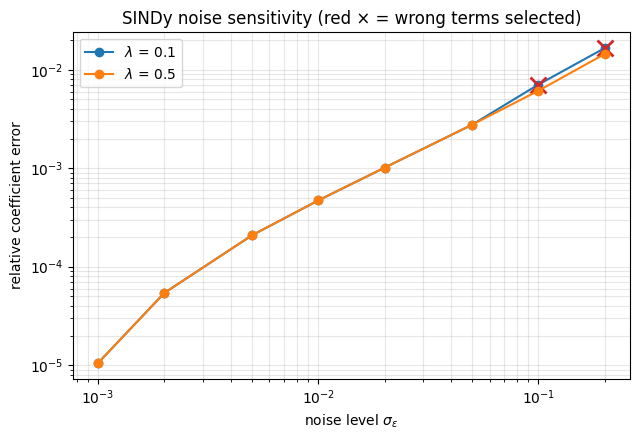

In [33]:
def add_noise(noise_std, key=noise_key):
    return X_clean + noise_std * random.normal(key, X_clean.shape)


def run_sindy_pipeline(noise_std, threshold=LAMBDA):
    # Steps 3-6 in one function: noise -> derivatives -> library -> STLSQ
    Xn = add_noise(noise_std)
    Xi_n, _ = stlsq(build_poly_library(Xn), finite_difference_4th(Xn, DT), threshold)
    return Xi_n


def rel_coef_error(Xi_est):
    return float(jnp.linalg.norm(Xi_est - Xi_true) / jnp.linalg.norm(Xi_true))


def correct_terms(Xi_est):
    return bool(jnp.array_equal(Xi_est != 0, Xi_true != 0))


noise_levels = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
plt.figure(figsize=(6.5, 4.5))
for lam, color in [(0.1, "#1f77b4"), (0.5, "#ff7f0e")]:
    errors, supports_ok = [], []
    for s in noise_levels:
        Xi_s = run_sindy_pipeline(s, threshold=lam)
        errors.append(rel_coef_error(Xi_s))
        supports_ok.append(correct_terms(Xi_s))
        print(f"lambda={lam}  sigma_eps={s:<6} rel. error={errors[-1]:.2e}  correct terms: {supports_ok[-1]}")
    plt.loglog(noise_levels, errors, "o-", color=color, label=rf"$\lambda$ = {lam}")
    bad = ~np.array(supports_ok)
    plt.loglog(noise_levels[bad], np.array(errors)[bad], "x", color="#d62728", ms=11, mew=2)
    print()
plt.xlabel(r"noise level $\sigma_\varepsilon$"); plt.ylabel("relative coefficient error")
plt.title("SINDy noise sensitivity (red × = wrong terms selected)")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.savefig("lorenz_noise_sensitivity.png", dpi=150); plt.show()

## Extension  Weak SINDy (WSINDy)



In [34]:
P_BUMP = 4        # smoothness of the bump
H_WIN = 0.1       # half-width of each test-function window (time units)
K_TEST = 300      # number of test functions


def phi(t_val, c, H=H_WIN, p=P_BUMP):
    tau = (t_val - c) / H
    return jnp.where(jnp.abs(tau) < 1.0, (1.0 - tau**2) ** p, 0.0)


def dphi_dt(t_val, c, H=H_WIN, p=P_BUMP):
    tau = (t_val - c) / H
    dphi_dtau = jnp.where(jnp.abs(tau) < 1.0, p * (1.0 - tau**2) ** (p - 1) * (-2.0 * tau), 0.0)
    return dphi_dtau / H                         # chain rule: d/dt = (1/H) d/dtau


def weak_matrices(X, t, H=H_WIN, K=K_TEST):
    # Build the weak-form system b = G @ Xi.
    dt = t[1] - t[0]
    centers = jnp.linspace(t[0] + H, t[-1] - H, K)
    # Outer vmap over the K centres, inner vmap over the N time points -> shape (K, N)
    V       = jax.vmap(lambda c: jax.vmap(lambda s: phi(s, c))(t))(centers) * dt
    V_prime = jax.vmap(lambda c: jax.vmap(lambda s: dphi_dt(s, c))(t))(centers) * dt
    b = -V_prime @ X                             # (K, 3)   LHS after integration by parts
    G = V @ build_poly_library(X)                # (K, 10)  integrated library
    return b, G


def support_mistakes(Xi_est):
    # List the terms that were wrongly kept (+) or wrongly dropped (-)
    Xi_est, truth = np.asarray(Xi_est), np.asarray(Xi_true)
    wrong = []
    for i, k in zip(*np.nonzero((Xi_est != 0) != (truth != 0))):
        sign = "+" if Xi_est[i, k] != 0 else "-"
        wrong.append(f"{sign}{FEATURE_NAMES[i]} in {EQS[k]}")
    return ", ".join(wrong) if wrong else "none"


LAMBDA_HIGH_NOISE = 0.5    # more noise -> larger threshold (Lecture 3, "Tuning lambda")
print(f"{'sigma_eps':>9} | {'method':>7} | {'rel. error':>10} | wrong terms")
print("-" * 60)
for s in [0.01, 0.1, 0.25, 0.5]:
    Xn = add_noise(s)
    lam = LAMBDA if s <= 0.01 else LAMBDA_HIGH_NOISE
    Xi_fd, _ = stlsq(build_poly_library(Xn), finite_difference_4th(Xn, DT), lam)
    b_w, G_w = weak_matrices(Xn, t)
    Xi_w, _ = stlsq(G_w, b_w, lam)
    for method, Xi_m in [("SINDy", Xi_fd), ("WSINDy", Xi_w)]:
        print(f"{s:>9} | {method:>7} | {rel_coef_error(Xi_m):10.2e} | {support_mistakes(Xi_m)}")

b_w, G_w = weak_matrices(X_noisy, t)
Xi_weak, _ = stlsq(G_w, b_w, LAMBDA)
print("\nWSINDy model at sigma_eps = 0.01:\n" + equations_as_text(Xi_weak))

sigma_eps |  method | rel. error | wrong terms
------------------------------------------------------------
     0.01 |   SINDy |   4.70e-04 | none
     0.01 |  WSINDy |   1.42e-04 | none
      0.1 |   SINDy |   6.12e-03 | none
      0.1 |  WSINDy |   1.41e-03 | none
     0.25 |   SINDy |   8.55e-02 | -y in dy/dt
     0.25 |  WSINDy |   3.57e-03 | none
      0.5 |   SINDy |   8.90e-02 | -y in dy/dt
      0.5 |  WSINDy |   7.61e-03 | none

WSINDy model at sigma_eps = 0.01:
dx/dt = -10.0036*x +10.0023*y
dy/dt = +27.9989*x -0.9991*y -1.0000*xz
dz/dt = -2.6668*z +1.0000*xy


## Extension Ensemble SINDy (E-SINDy)


 term |  P(dx/dt)  P(dy/dt)  P(dz/dt)
--------------------------------------
    1 |      0.00      0.00      0.22
    x |      1.00      1.00      0.00
    y |      1.00      1.00      0.00
    z |      0.00      0.00      1.00
  x^2 |      0.00      0.00      0.00
   xy |      0.00      0.00      1.00
   xz |      0.00      1.00      0.00
  y^2 |      0.00      0.00      0.00
   yz |      0.00      0.00      0.00
  z^2 |      0.00      0.00      0.00

E-SINDy model 
   dx/dt    x:  -10.0017   [-10.0179, -9.9877]
   dy/dt    x:   27.9956   [27.9369, 28.0418]
   dx/dt    y:   10.0005   [9.9871, 10.0165]
   dy/dt    y:   -0.9973   [-1.0158, -0.9764]
   dz/dt    z:   -2.6672   [-2.6729, -2.6619]
   dz/dt   xy:    1.0000   [0.9994, 1.0006]
   dy/dt   xz:   -0.9999   [-1.0011, -0.9986]


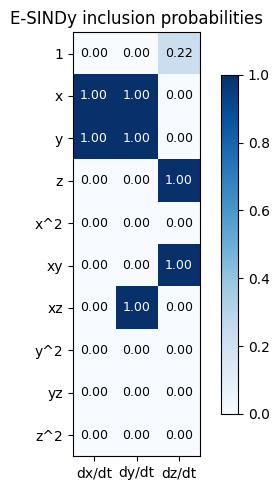

In [36]:
def ensemble_sindy(Theta, Xdot, threshold, n_boot, key):
    n = Theta.shape[0]
    fits = []
    for k in random.split(key, n_boot):                         # one independent key per bootstrap
        rows = random.choice(k, n, shape=(n,), replace=True)    # sample rows with replacement
        Xi_b, _ = stlsq(Theta[rows], Xdot[rows], threshold)
        fits.append(Xi_b)
    return jnp.stack(fits)                                      # (n_boot, 10, 3)


key, boot_key = random.split(key)
ens = ensemble_sindy(Theta, Xdot, LAMBDA, n_boot=100, key=boot_key)

incl_prob = jnp.mean(ens != 0, axis=0)
Xi_median = jnp.median(ens, axis=0)
Xi_esindy = jnp.where(incl_prob > 0.5, Xi_median, 0.0)
lo, hi = jnp.percentile(ens, jnp.array([2.5, 97.5]), axis=0)

print(f"{'term':>5} | {'P(dx/dt)':>9} {'P(dy/dt)':>9} {'P(dz/dt)':>9}")
print("-" * 38)
for name, row in zip(FEATURE_NAMES, np.asarray(incl_prob)):
    print(f"{name:>5} | " + " ".join(f"{v:9.2f}" for v in row))

print("\nE-SINDy model ")
for i, k in zip(*np.nonzero(np.asarray(Xi_esindy))):
    print(f"  {EQS[k]:>6}  {FEATURE_NAMES[i]:>3}: {float(Xi_esindy[i, k]):9.4f}   "
          f"[{float(lo[i, k]):.4f}, {float(hi[i, k]):.4f}]")

P = np.asarray(incl_prob)
fig, ax = plt.subplots(figsize=(4.5, 5))
im = ax.imshow(P, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3), EQS); ax.set_yticks(range(10), FEATURE_NAMES)
for i in range(10):
    for k in range(3):
        ax.text(k, i, f"{P[i, k]:.2f}", ha="center", va="center",
                color="white" if P[i, k] > 0.5 else "black", fontsize=9)
ax.set_title("E-SINDy inclusion probabilities")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()